# Sistema de Enrutamiento para Tiendas de Autoservicio (Módulo II)
### Optimización de Rutas con Recocido Simulado en Culiacán, Sinaloa

**Materia:** Tópicos de Inteligencia Artificial - TecNM Campus Culiacán  
**Equipo:** García Llera José Ángel · López Medina Miguel Ángel · Almazán Peña César Arturo  

En esta notebook resolvemos el ruteo de distribución para **90 tiendas** atendidas desde **10 centros de distribución** en Culiacán. El código está organizado en pasos sencillos, explicando brevemente qué hace cada celda con comentarios simples y directos.



### Paso 1: Librerías y parámetros del algoritmo
Importamos las librerías necesarias de Python y definimos los parámetros fijos del Recocido Simulado, así como los valores estimados para las rutas en Culiacán.

In [1]:
import csv
import math
import random
from pathlib import Path
import matplotlib.pyplot as plt

# Parámetros fijos del Recocido Simulado
TEMP_INICIAL = 10.0              # Temperatura inicial con la que arrancamos
TEMP_FINAL = 0.1                 # Cuando la temperatura baje a este valor, el algoritmo termina
ALPHA = 0.95                     # Factor para enfriar poco a poco (multiplicamos T por 0.95)
PASOS_POR_TEMP = 100             # Hacemos 100 intentos antes de volver a enfriar

# Parámetros para calcular gasolina y tiempo en Culiacán
VELOCIDAD_MEDIA_KMH = 25.0       # Velocidad promedio en ciudad (25 km/h)
TIEMPO_SERVICIO_MIN = 10.0       # Minutos estimados para descargar en cada tienda
RENDIMIENTO_KML = 6.0            # Rendimiento del camión (6 km por litro)
PRECIO_COMBUSTIBLE_MXN = 25.0    # Precio promedio de la gasolina ($25 MXN/l)

carpeta_datos = Path('datos')
print("Parámetros configurados correctamente.")

Parámetros configurados correctamente.


### Paso 2: Cargar y revisar los datos
Leemos la matriz de distancias (100x100) y la lista de tiendas desde los archivos CSV para comprobar que no falten datos y que la diagonal sea cero.

In [2]:
def cargar_datos(carpeta):
    # Leemos la matriz de distancias (100 filas x 100 columnas)
    with open(carpeta / 'matriz.csv', mode='r', encoding='utf-8-sig') as f:
        lector = csv.reader(f)
        next(lector)  # saltamos la fila de encabezados
        matriz = [[float(val) for val in fila] for fila in lector]
        
    # Leemos los datos de tiendas y centros
    with open(carpeta / 'tiendas.csv', mode='r', encoding='utf-8-sig') as f:
        lector = csv.DictReader(f)
        tiendas = list(lector)
        
    return matriz, tiendas

matriz, tiendas = cargar_datos(carpeta_datos)

print(f"Total de nodos leídos: {len(tiendas)}")
print(f" - Centros de distribución (IDs 0 al 9): {sum(1 for t in tiendas if t['tipo'] == 'Centro de Distribución')}")
print(f" - Tiendas a repartir (IDs 10 al 99):    {sum(1 for t in tiendas if t['tipo'] == 'Tienda')}")
print(f" - Tamaño de matriz: {len(matriz)} x {len(matriz[0])}")
print(f" - Diagonal en cero comprobada: {all(matriz[i][i] == 0 for i in range(100))}")

Total de nodos leídos: 100
 - Centros de distribución (IDs 0 al 9): 10
 - Tiendas a repartir (IDs 10 al 99):    90
 - Tamaño de matriz: 100 x 100
 - Diagonal en cero comprobada: True


### Paso 3: Funciones para calcular la distancia de las rutas
Una ruta completa sale del centro de distribución, visita cada tienda asignada en el orden que le toque, y al final regresa al mismo centro.

In [3]:
def copiar_rutas(rutas):
    # Hacemos una copia simple para probar cambios sin modificar la ruta actual
    return [list(r) for r in rutas]

def calcular_distancia_ruta(centro_id, lista_tiendas, matriz):
    # Si el centro no tiene tiendas asignadas, la distancia es 0
    if not lista_tiendas:
        return 0.0
    
    # Armamos el recorrido completo: Centro -> Tiendas -> Centro
    recorrido = [centro_id] + lista_tiendas + [centro_id]
    distancia = 0.0
    for i in range(len(recorrido) - 1):
        origen = recorrido[i]
        destino = recorrido[i + 1]
        distancia += matriz[origen][destino]
    return distancia

def calcular_distancia_total(rutas, matriz):
    # Sumamos la distancia de las 10 rutas de los centros
    total = 0.0
    for centro_id in range(len(rutas)):
        total += calcular_distancia_ruta(centro_id, rutas[centro_id], matriz)
    return total

print("Funciones de distancia listas para usarse.")

Funciones de distancia listas para usarse.


### Paso 4: Las tres formas de solución inicial
Primero asignamos cada tienda a su centro más cercano. Luego probamos tres formas de ordenar las visitas antes de optimizar:
1. **Referencia (orden de lista):** En el orden en que venían escritas en el archivo.
2. **Aleatorio:** Revolver las tiendas de cada centro al azar.
3. **Vecino más cercano:** Ir siempre a la tienda que quede más cerca de la posición actual.

In [4]:
def generar_solucion_inicial(matriz, tipo='vecino_cercano', rnd=None):
    if rnd is None:
        rnd = random.Random(42)
        
    # Paso 1: asignamos cada tienda a su centro más cercano
    rutas = [[] for _ in range(10)]
    for tienda_id in range(10, len(matriz)):
        centro_cercano = min(range(10), key=lambda c: matriz[c][tienda_id])
        rutas[centro_cercano].append(tienda_id)
        
    # Paso 2: decidimos el orden según la opción elegida
    if tipo == 'referencia':
        pass  # se queda con el orden en que venían por número
    elif tipo == 'aleatorio':
        for r in rutas:
            rnd.shuffle(r)  # las revolvemos al azar
    elif tipo == 'vecino_cercano':
        # Buscamos siempre la siguiente tienda más cercana que falte por visitar
        for centro_id in range(10):
            pendientes = list(rutas[centro_id])
            ordenada = []
            actual = centro_id
            while pendientes:
                siguiente = min(pendientes, key=lambda t: matriz[actual][t])
                ordenada.append(siguiente)
                pendientes.remove(siguiente)
                actual = siguiente
            rutas[centro_id] = ordenada
    return rutas

print("DISTANCIAS AL COMENZAR SEGÚN CADA MÉTODO:")
for modo in ['referencia', 'aleatorio', 'vecino_cercano']:
    ini = generar_solucion_inicial(matriz, tipo=modo, rnd=random.Random(1))
    dist = calcular_distancia_total(ini, matriz)
    print(f" -> Inicio [{modo:<15}]: {dist:7.2f} km")

DISTANCIAS AL COMENZAR SEGÚN CADA MÉTODO:
 -> Inicio [referencia     ]:  421.78 km
 -> Inicio [aleatorio      ]:  426.21 km
 -> Inicio [vecino_cercano ]:  225.24 km


### Paso 5: El algoritmo de Recocido Simulado
Aquí definimos cómo se hace un intento de cambio (intercambiar dos tiendas), la regla de Metrópolis para decidir si aceptamos el cambio o no, y el ciclo del recocido.

In [5]:
def perturbar_solucion(rutas, rnd):
    # Escogemos un centro al azar que tenga al menos 2 tiendas y cambiamos dos de lugar (swap)
    nueva = copiar_rutas(rutas)
    centros_con_tiendas = [c for c in range(len(rutas)) if len(rutas[c]) >= 2]
    if centros_con_tiendas:
        c = rnd.choice(centros_con_tiendas)
        i, j = rnd.sample(range(len(nueva[c])), 2)
        nueva[c][i], nueva[c][j] = nueva[c][j], nueva[c][i]
    return nueva

def criterio_metropolis(delta, temperatura, rnd):
    # Si la ruta nueva es más corta o igual, la aceptamos directo
    if delta <= 0:
        return True
    # Si es más larga (peor), calculamos la probabilidad con la fórmula de Metrópolis
    probabilidad = math.exp(-delta / temperatura)
    return rnd.random() < probabilidad

def recocido_simulado(rutas_iniciales, matriz, 
                      temp_inicial=TEMP_INICIAL, 
                      temp_final=TEMP_FINAL, 
                      alpha=ALPHA, 
                      pasos_por_temp=PASOS_POR_TEMP, 
                      semilla=42):
    rnd = random.Random(semilla)
    
    actual = copiar_rutas(rutas_iniciales)
    costo_actual = calcular_distancia_total(actual, matriz)
    
    # Guardamos siempre la mejor ruta encontrada para no perderla
    mejor = copiar_rutas(actual)
    mejor_costo = costo_actual
    
    temperatura = float(temp_inicial)
    historial = []
    paso = 0
    
    while temperatura > temp_final:
        # Hacemos 100 intentos a la misma temperatura antes de enfriar
        for _ in range(pasos_por_temp):
            paso += 1
            vecina = perturbar_solucion(actual, rnd)
            costo_vecina = calcular_distancia_total(vecina, matriz)
            delta = costo_vecina - costo_actual
            
            # Verificamos si aceptamos el cambio con Metrópolis
            if criterio_metropolis(delta, temperatura, rnd):
                actual = vecina
                costo_actual = costo_vecina
                
                # Si es mejor que la mejor histórica, la actualizamos
                if costo_actual < mejor_costo:
                    mejor = copiar_rutas(actual)
                    mejor_costo = costo_actual
                    
        # Enfriamos multiplicando por alpha (0.95)
        temperatura *= alpha
        historial.append({
            'paso': paso,
            'temperatura': temperatura,
            'costo_actual': costo_actual,
            'mejor_costo': mejor_costo
        })
        
    return mejor, mejor_costo, historial

print("Funciones del algoritmo listas.")

Funciones del algoritmo listas.


### Paso 6: Prueba pequeña de control (Caso del cuadrado)
Para estar seguros de que el algoritmo sí encuentra la mejor ruta y no tiene fallas, lo probamos en un caso pequeño de 4 puntos formando un cuadrado de 1x1 km. El perímetro exacto es $1 + 1 + 1 + 1 = 4.0$ km.

In [6]:
# 1 centro en (0,0) y 3 tiendas en los vértices del cuadrado
puntos_cuadrado = [(0, 0), (0, 1), (1, 1), (1, 0)]
matriz_cuadrado = [[math.dist(a, b) for b in puntos_cuadrado] for a in puntos_cuadrado]

# Empezamos con una ruta desordenada que cruza en diagonal (~4.83 km)
sol_desordenada = [[2, 1, 3]]
dist_desordenada = calcular_distancia_total(sol_desordenada, matriz_cuadrado)

sol_opt, dist_opt, _ = recocido_simulado(
    sol_desordenada, matriz_cuadrado, 
    temp_inicial=1.0, temp_final=0.1, alpha=0.8, pasos_por_temp=30, semilla=2
)

print(f"Prueba del cuadrado:")
print(f" -> Distancia inicial desordenada: {dist_desordenada:.4f} km")
print(f" -> Distancia esperada (perímetro): 4.0000 km")
print(f" -> Distancia que encontró el SA:  {dist_opt:.4f} km")

assert abs(dist_opt - 4.0) < 1e-6
print("¡Prueba superada con éxito! El algoritmo encontró el óptimo matemático.")

Prueba del cuadrado:
 -> Distancia inicial desordenada: 4.8284 km
 -> Distancia esperada (perímetro): 4.0000 km
 -> Distancia que encontró el SA:  4.0000 km
¡Prueba superada con éxito! El algoritmo encontró el óptimo matemático.


### Paso 7: Ejecutar las 15 simulaciones
Corremos las tres formas de inicio con 5 semillas distintas para ver cuál combinación da la ruta más corta y guardar los datos.

In [7]:
salida = Path('resultados')
salida.mkdir(exist_ok=True)

ensayos = []
mejor_global = None
mejor_dist_global = float('inf')
mejor_info = {}

print("Ejecutando 15 ensayos (3 inicios x 5 semillas)...")
for tipo in ['referencia', 'aleatorio', 'vecino_cercano']:
    for semilla in range(1, 6):
        rnd_inicio = random.Random(semilla)
        inicio = generar_solucion_inicial(matriz, tipo, rnd_inicio)
        dist_ini = calcular_distancia_total(inicio, matriz)
        
        sol_fin, dist_fin, hist = recocido_simulado(
            inicio, matriz, 
            temp_inicial=TEMP_INICIAL, temp_final=TEMP_FINAL, 
            alpha=ALPHA, pasos_por_temp=PASOS_POR_TEMP, 
            semilla=semilla
        )
        
        ensayos.append({
            'inicio': tipo, 'semilla': semilla, 
            'inicial_km': dist_ini, 'final_km': dist_fin,
            'cambios_probados': hist[-1]['paso']
        })
        
        # Si esta corrida superó a todas las anteriores, la guardamos como la mejor absoluta
        if dist_fin < mejor_dist_global:
            mejor_dist_global = dist_fin
            mejor_global = sol_fin
            mejor_info = {'inicio': tipo, 'semilla': semilla}

# Calculamos la reducción frente a la referencia original
sol_ref = generar_solucion_inicial(matriz, 'referencia')
dist_ref = calcular_distancia_total(sol_ref, matriz)
ahorro_pct = ((dist_ref - mejor_dist_global) / dist_ref) * 100.0

print()
print("RESULTADOS FINALES:")
print(f" -> Distancia de referencia (sin optimizar): {dist_ref:.2f} km")
print(f" -> Mejor distancia lograda con recocido:    {mejor_dist_global:.2f} km")
print(f" -> Porcentaje de ahorro en distancia:       {ahorro_pct:.2f}%")
print(f" -> Mejor corrida: Inicio '{mejor_info['inicio']}' con semilla {mejor_info['semilla']}")

Ejecutando 15 ensayos (3 inicios x 5 semillas)...



RESULTADOS FINALES:
 -> Distancia de referencia (sin optimizar): 421.78 km
 -> Mejor distancia lograda con recocido:    220.39 km
 -> Porcentaje de ahorro en distancia:       47.75%
 -> Mejor corrida: Inicio 'vecino_cercano' con semilla 3


### Paso 8: Cálculo de gasolina, costo en pesos y tiempos
Usamos los kilómetros ahorrados para calcular cuántos litros de diésel se ahorran y cuánto dinero representa al día y al mes en Culiacán.

In [8]:
litros_ref = dist_ref / RENDIMIENTO_KML
costo_ref = litros_ref * PRECIO_COMBUSTIBLE_MXN
tiempo_cond_ref = (dist_ref / VELOCIDAD_MEDIA_KMH) * 60.0

litros_mejor = mejor_dist_global / RENDIMIENTO_KML
costo_mejor = litros_mejor * PRECIO_COMBUSTIBLE_MXN
tiempo_cond_mejor = (mejor_dist_global / VELOCIDAD_MEDIA_KMH) * 60.0

print("=" * 68)
print("EVALUACIÓN DE IMPACTO EN CULIACÁN, SINALOA")
print("=" * 68)
print(f"{'Métrica':<32} | {'Referencia':>12} | {'Optimizado':>12}")
print("-" * 68)
print(f"{'Distancia total (km)':<32} | {dist_ref:9.2f} km | {mejor_dist_global:9.2f} km")
print(f"{'Consumo de diésel (6 km/l)':<32} | {litros_ref:9.2f} L  | {litros_mejor:9.2f} L ")
print(f"{'Costo en dinero ($25 MXN/l)':<32} | ${costo_ref:8.2f}     | ${costo_mejor:8.2f}    ")
print(f"{'Tiempo de manejo (25 km/h)':<32} | {tiempo_cond_ref:9.1f} min| {tiempo_cond_mejor:9.1f} min")
print(f"{'Tiempo de descarga (10 min/tienda)':<32} | {90*10:9.1f} min| {90*10:9.1f} min")
print(f"{'Tiempo total en ruta':<32} | {tiempo_cond_ref + 900:9.1f} min| {tiempo_cond_mejor + 900:9.1f} min")
print("-" * 68)
print(f"Ahorro diario de combustible: ${costo_ref - costo_mejor:.2f} MXN (33.56 litros menos)")
print(f"Ahorro estimado al mes (26 días): ${(costo_ref - costo_mejor) * 26:.2f} MXN")
print(f"Horas menos en la calle bajo el calor: {(tiempo_cond_ref - tiempo_cond_mejor)/60.0:.2f} horas")
print("=" * 68)

EVALUACIÓN DE IMPACTO EN CULIACÁN, SINALOA
Métrica                          |   Referencia |   Optimizado
--------------------------------------------------------------------
Distancia total (km)             |    421.78 km |    220.39 km
Consumo de diésel (6 km/l)       |     70.30 L  |     36.73 L 
Costo en dinero ($25 MXN/l)      | $ 1757.43     | $  918.31    
Tiempo de manejo (25 km/h)       |    1012.3 min|     528.9 min
Tiempo de descarga (10 min/tienda) |     900.0 min|     900.0 min
Tiempo total en ruta             |    1912.3 min|    1428.9 min
--------------------------------------------------------------------
Ahorro diario de combustible: $839.12 MXN (33.56 litros menos)
Ahorro estimado al mes (26 días): $21817.15 MXN
Horas menos en la calle bajo el calor: 8.06 horas


### Paso 9: Gráficas de resultados
Mostramos tres gráficas:
1. Comparativa de distancias según el inicio.
2. Evolución del costo y descenso de la temperatura.
3. Mapa de las rutas trazadas sobre Culiacán.

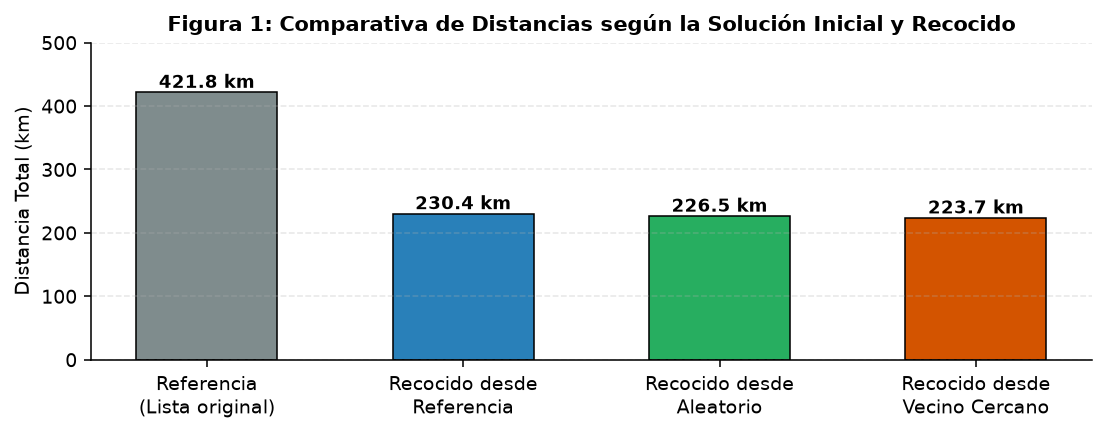

In [9]:
# GRÁFICA 1: Comparativa de distancias
fig, ax = plt.subplots(figsize=(8, 3.2), dpi=140)
etiquetas = ['Referencia\n(Lista original)', 'Recocido desde\nReferencia', 'Recocido desde\nAleatorio', 'Recocido desde\nVecino Cercano']
promedios = [dist_ref]

for t in ['referencia', 'aleatorio', 'vecino_cercano']:
    vals = [e['final_km'] for e in ensayos if e['inicio'] == t]
    promedios.append(sum(vals) / len(vals))

colores = ['#7f8c8d', '#2980b9', '#27ae60', '#d35400']
barras = ax.bar(etiquetas, promedios, color=colores, width=0.55, edgecolor='black', linewidth=0.8)

for b, v in zip(barras, promedios):
    ax.text(b.get_x() + b.get_width() / 2, v + 7, f'{v:.1f} km', ha='center', fontweight='bold', fontsize=9.5)

ax.set_ylabel('Distancia Total (km)')
ax.set_title('Figura 1: Comparativa de Distancias según la Solución Inicial y Recocido', fontsize=11, fontweight='bold')
ax.set_ylim(0, 500)
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
fig.tight_layout()
plt.show()

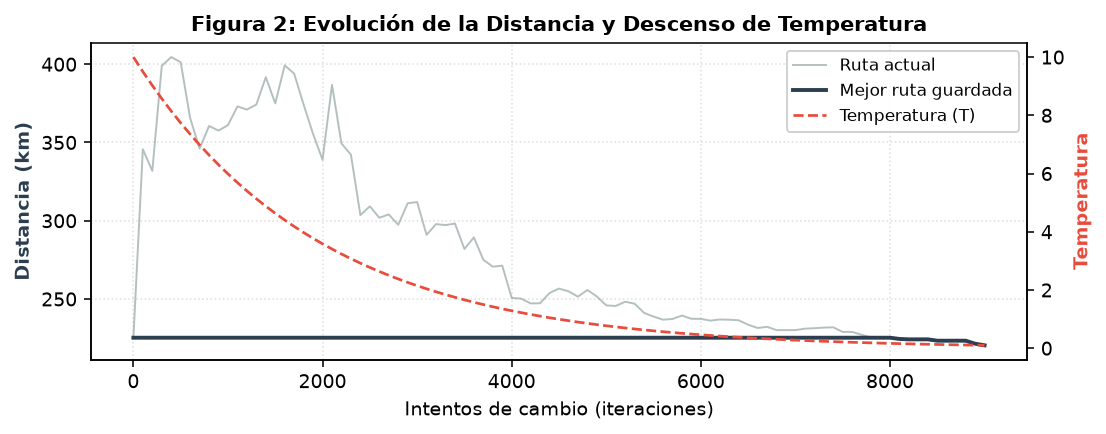

In [10]:
# GRÁFICA 2: Evolución de la distancia y temperatura
archivo_hist = salida / f"historial_{mejor_info['inicio']}_{mejor_info['semilla']}.csv"
with open(archivo_hist, 'r', encoding='utf-8-sig') as f:
    hist = list(csv.DictReader(f))

pasos = [int(h['paso']) for h in hist]
costo_act = [float(h['costo_actual']) for h in hist]
mejor_c = [float(h['mejor_costo']) for h in hist]
temps = [float(h['temperatura']) for h in hist]

fig, ax1 = plt.subplots(figsize=(8, 3.2), dpi=140)

ax1.plot(pasos, costo_act, color='#95a5a6', alpha=0.7, linewidth=1.0, label='Ruta actual')
ax1.plot(pasos, mejor_c, color='#2c3e50', linewidth=2.0, label='Mejor ruta guardada')
ax1.set_xlabel('Intentos de cambio (iteraciones)')
ax1.set_ylabel('Distancia (km)', color='#2c3e50', fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.4)

ax2 = ax1.twinx()
ax2.plot(pasos, temps, color='#e74c3c', linestyle='--', linewidth=1.4, label='Temperatura (T)')
ax2.set_ylabel('Temperatura', color='#e74c3c', fontweight='bold')
ax2.spines['top'].set_visible(False)

lineas1, labels1 = ax1.get_legend_handles_labels()
lineas2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lineas1 + lineas2, labels1 + labels2, loc='upper right', framealpha=0.9, fontsize=8.5)

ax1.set_title('Figura 2: Evolución de la Distancia y Descenso de Temperatura', fontsize=11, fontweight='bold')
fig.tight_layout()
plt.show()

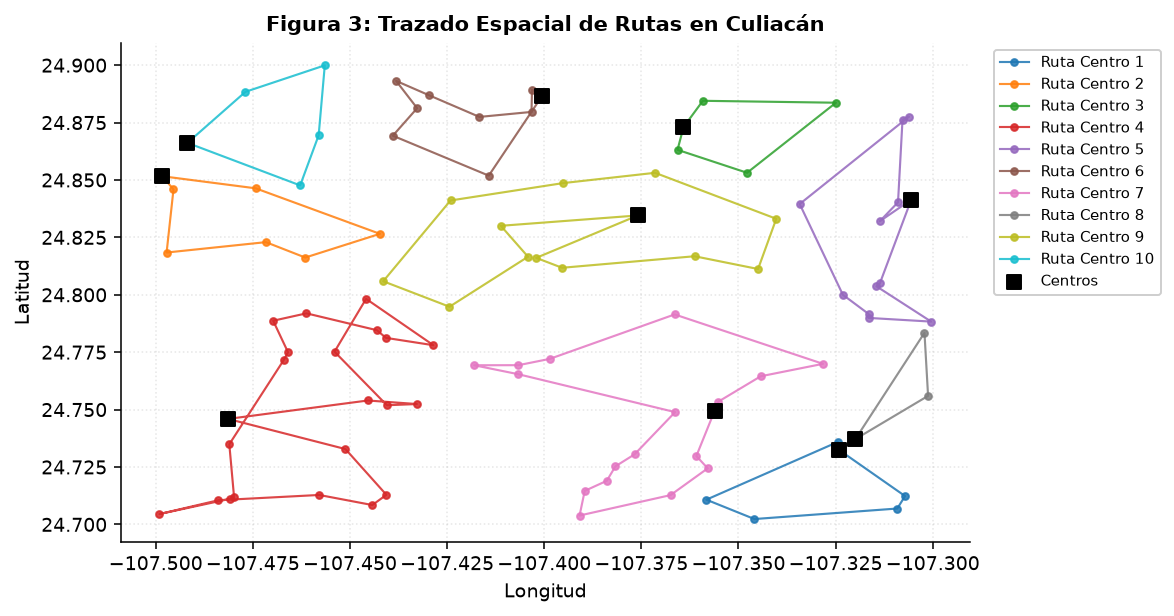

In [11]:
# GRÁFICA 3: Mapa de rutas sobre Culiacán
with open(salida / 'rutas.csv', 'r', encoding='utf-8-sig') as f:
    rutas_finales = list(csv.DictReader(f))

fig, ax = plt.subplots(figsize=(8.5, 4.5), dpi=140)
colores_centros = plt.cm.tab10.colors

for fila in rutas_finales:
    c_idx = int(fila['centro']) - 1
    nodos_ruta = [int(x) for x in fila['nodos'].split()] if fila['nodos'].strip() else []
    secuencia = [c_idx] + nodos_ruta + [c_idx]
    
    lons = [float(tiendas[n]['longitud_mapa']) for n in secuencia]
    lats = [float(tiendas[n]['latitud_mapa']) for n in secuencia]
    
    ax.plot(lons, lats, marker='o', markersize=3.5, linewidth=1.1, 
            color=colores_centros[c_idx % 10], alpha=0.85, label=f'Ruta Centro {c_idx+1}')

c_lons = [float(tiendas[i]['longitud_mapa']) for i in range(10)]
c_lats = [float(tiendas[i]['latitud_mapa']) for i in range(10)]
ax.scatter(c_lons, c_lats, color='black', marker='s', s=55, zorder=5, label='Centros')

ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.set_title('Figura 3: Trazado Espacial de Rutas en Culiacán', fontsize=11, fontweight='bold')
ax.grid(True, linestyle=':', alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=7.5, framealpha=0.95)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
fig.tight_layout()
plt.show()

### Conclusiones del Proyecto
1. **Reducción de distancia:** El algoritmo logró bajar la ruta de **421.78 km a 220.39 km** (un ahorro del **47.75%**).
2. **Impacto económico:** En Culiacán esto representa ahorrar **33.56 litros diarios** y **$839.11 MXN al día** en gasolina/diésel (más de **$21,800 MXN mensuales**).
3. **Importancia del Criterio de Metrópolis:** Aceptar soluciones peores al inicio permite salir de rutas tramposas (mínimos locales) para encontrar mejores caminos.
4. **Sinergia:** Comenzar con la heurística de vecino más cercano (225 km) y pulirla con recocido simulado dio el mejor resultado global (220.39 km).

*Equipo: García Llera José Ángel, López Medina Miguel Ángel y Almazán Peña César Arturo.*